# Detecting settlements using supervised classification and deep learning

- 🔬 Data Science
- 🥠 Deep Learning and pixel-based classification

## Table of Contents
* [Introduction](#Introduction)
* [Necessary imports](#Necessary-imports)
* [Connect to your GIS](#Connect-to-your-GIS)
* [Get the data for analysis](#Get-the-data-for-analysis)
* [Filter satellite Imageries based on cloud cover and time duration](#Filter-satellite-Imageries-based-on-cloud-cover-and-time-duration)
* [Visualize the mosaic and training points on map](#Visualize-the-mosaic-and-training-points-on-map)
* [Classification](#Classification)
 * [Mask settlements out of the classified raster](#Mask-settlements-out-of-the-classified-raster)
* [Deep Learning](#Deep-Learning)
 * [Export training data](#Export-training-data)
 * [Prepare data](#Prepare-data)
 * [Visualize training data](#Visualize-training-data)
 * [Load model architecture](#Load-model-architecture)
 * [Train the model](#Train-the-model)
 * [Save the model](#Save-the-model)
 * [Load an intermediate model to train it further](#Load-an-intermediate-model-to-train-it-further)
 * [Preview results](#Preview-results)
* [Deploy model and extract settlements](#Deploy-model-and-extract-settlements)
 * [Generate a classified raster](#Generate-a-classified-raster)
* [Conclusion](#Conclusion)
* [References](#References)

## Introduction

Deep-Learning methods tend to perform well with high amounts of data as compared to machine learning methods which is one of the drawbacks of these models. These methods have also been used in geospatial domain to detect objects [1,2] and land use classification [3] which showed favourable results, but labelled input satellite data has always been an effortful task. In that regards, in this notebook we have attempted to use the supervised classification approach to generate the required volumes of data which after cleaning was used to come through the requirement of larger training data for Deep Learning model.

For this, we have considered detecting settlements for Saharanpur district in Uttar Pradesh, India. Settlements have their own importance to urban planners and monitoring them temporally can lay the foundation to design urban policies for any government. 

<img src="data:image/PNG; base64, ...">


## Necessary imports

In [1]:
%matplotlib inline

import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt

import arcgis
from arcgis.gis import GIS
from arcgis.geocoding import geocode
from arcgis.geometry import Geometry
from arcgis.learn import prepare_data, UnetClassifier
from arcgis.raster.functions import clip, apply, extract_band, colormap, mask, stretch
from arcgis.raster.analytics import train_classifier, classify, list_datastore_content

## Connect to your GIS

In [2]:
gis = GIS('home')

## Get the data for analysis

Search for <b>Multispectral Landsat</b> layer in ArcGIS Online. We can search for content shared by users outside our organization by setting <b>outside_org</b> to True.

<Item title:"Multispectral Landsat" type:Imagery Layer owner:esri>
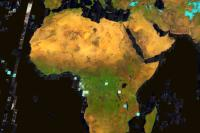

In [3]:
landsat_item = gis.content.search('title:Multispectral Landsat', 'Imagery Layer', outside_org=True)[0]
landsat = landsat_item.layers[0]
landsat_item

Search for India State Boundaries 2018 layer in ArcGIS Online. This layer has all the District boundaries for India at index - 2.

<Item title:"India: District Boundary 2024" type:Feature Layer Collection owner:esri_IN_content0>
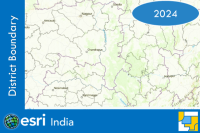

In [4]:
boundaries = gis.content.get('76f5897f7e354d399d261dac03af2ae3')
boundaries

In [5]:
district_boundaries = boundaries.layers[0]
district_boundaries

<MapFeatureLayer url:"https://livingatlas.esri.in/server/rest/services/IAB2024/IAB_District_2024/MapServer/0">

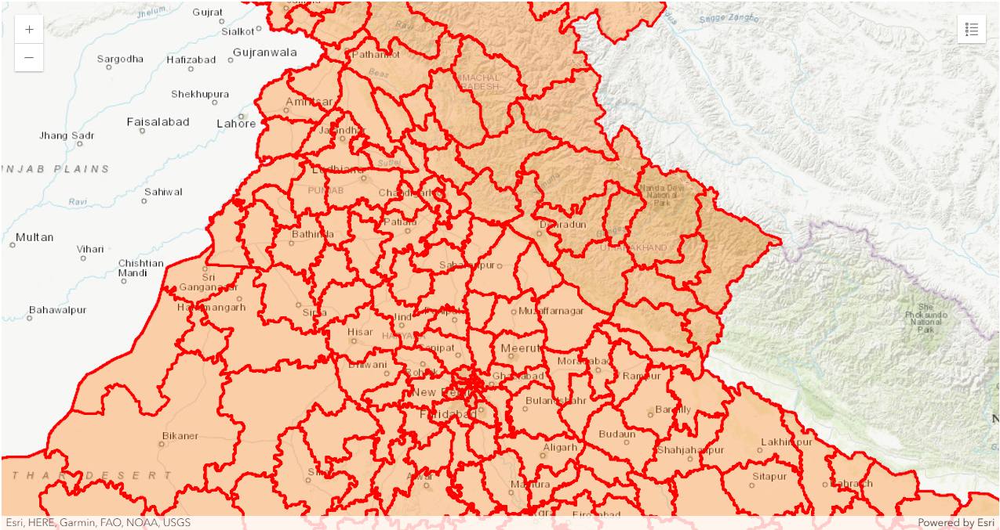

In [6]:
from arcgis.map.symbols import SimpleFillSymbolEsriSFS
from arcgis.map.symbols import SimpleLineSymbolEsriSLS
from arcgis.map.renderers import SimpleRenderer

m = gis.map('Saharanpur, India')

outline = SimpleLineSymbolEsriSLS(type = "esriSLS", style = "esriSLSSolid", color = [255, 0, 0, 255], width = 2)
symbol = SimpleFillSymbolEsriSFS(outline = outline, style = "esriSFSSolid", color = [255, 120, 0, 80])
renderer = SimpleRenderer(symbol = symbol)

m.content.add(district_boundaries, drawing_info = {"renderer":renderer}, options = {"title":"District Boundaries"})

m.legend.enabled = True
m

In [7]:
m.zoom = 7

As this notebook is to detect settlements for Saharanpur district, you can filter the boundary for Saharanpur.

In [8]:
area = geocode("Saharanpur, India", out_sr = landsat.properties.spatialReference)[0]

In [9]:
saharanpur = district_boundaries.query(where = "ID = '9177673'")   # query for Saharanur district boundary
saharanpur_geom = saharanpur.features[0].geometry                  # Extracting geometry of Saharanpur district boundary   

extent = dict(Geometry(saharanpur_geom).envelope)                  # Set the extent
landsat.extent = extent
saharanpur.features[0].extent = extent                     

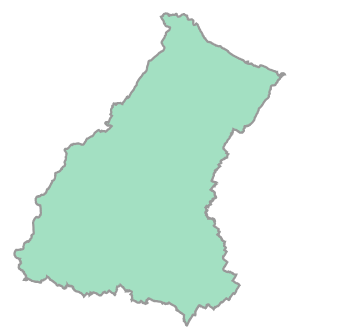

In [10]:
Geometry(saharanpur_geom)

Get the training points for training the classifier. These are 212 points in total marked against 5 different classes namely <b>Urban</b>, <b>Forest</b>, <b>Agricultural</b>, <b>Water</b> and <b>Wasteland</b>. These points are marked using ArcGIS pro and pulished on the gis server.

<Item title:"classificationPointsSaharanpur_Projected" type:Feature Layer Collection owner:api_data_owner>
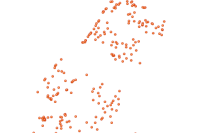

In [11]:
data = gis.content.get('0e03348c4d4145fa9bcacc4c800c055e')
data

## Filter satellite Imagery based on cloud cover and time duration

In order to produce good results, it is important to select cloud free imagery from the image collection for a specified time duration. In this example we have selected all the images captured between 1 October 2018 to 31 December 2018 with cloud cover less than or equal to 5% for Saharanpur region.

In [12]:
selected = landsat.filter_by(where="(Category = 1) AND (cloudcover <=0.05)",
                             time=[datetime.datetime(2024, 3, 1), 
                                   datetime.datetime(2024, 7, 31)],
                             geometry=arcgis.geometry.filters.intersects(area['extent']))
df = selected.query(out_fields="AcquisitionDate, GroupName, CloudCover, DayOfYear", 
                    order_by_fields="AcquisitionDate").sdf
df['AcquisitionDate'] = pd.to_datetime(df['AcquisitionDate'], unit='ms')
df

,OBJECTID,AcquisitionDate,GroupName,CloudCover,DayOfYear,SHAPE
0,5013202,2024-03-08 05:18:43,LC08_L1TP_146040_20240308_20240315_02_T1_MTL,0.0003,40,"{""rings"": [[[8796000.0984, 3442899.6076999977]..."
1,5035681,2024-03-15 05:24:28,LC08_L1TP_147039_20240315_20240401_02_T1_MTL,0.0002,39,"{""rings"": [[[8666740.7075, 3627836.4750000015]..."
2,5024810,2024-03-23 05:24:45,LC09_L1TP_147039_20240323_20240323_02_T1_MTL,0.001,39,"{""rings"": [[[8664390.306899998, 3627647.700999..."
3,5049737,2024-04-08 05:24:37,LC09_L1TP_147039_20240408_20240408_02_T1_MTL,0.0015,39,"{""rings"": [[[8664874.682, 3627657.164499998], ..."
4,5076600,2024-04-16 05:24:09,LC08_L1TP_147039_20240416_20240423_02_T1_MTL,0.0336,39,"{""rings"": [[[8666288.433200002, 3627938.365800..."
5,5066173,2024-04-17 05:18:18,LC09_L1TP_146039_20240417_20240417_02_T1_MTL,0.0192,39,"{""rings"": [[[8837873.4065, 3627741.8351000026]..."
6,5066174,2024-04-17 05:18:42,LC09_L1TP_146040_20240417_20240417_02_T1_MTL,0.0005,40,"{""rings"": [[[8795108.6435, 3442745.924900003],..."
7,5079393,2024-04-24 05:24:15,LC09_L1TP_147039_20240424_20240424_02_T1_MTL,0.017,39,"{""rings"": [[[8671082.293699998, 3627628.717200..."
8,5100253,2024-04-25 05:17:54,LC08_L1TP_146039_20240425_20240510_02_T1_MTL,0.0418,39,"{""rings"": [[[8837330.6147, 3628004.6987000033]..."
9,5100254,2024-04-25 05:18:18,LC08_L1TP_146040_20240425_20240510_02_T1_MTL,0.0006,40,"{""rings"": [[[8794622.175500002, 3442817.626699..."


We can now select the image dated 17 April 2024 from the collection using its OBJECTID which is "5066173"

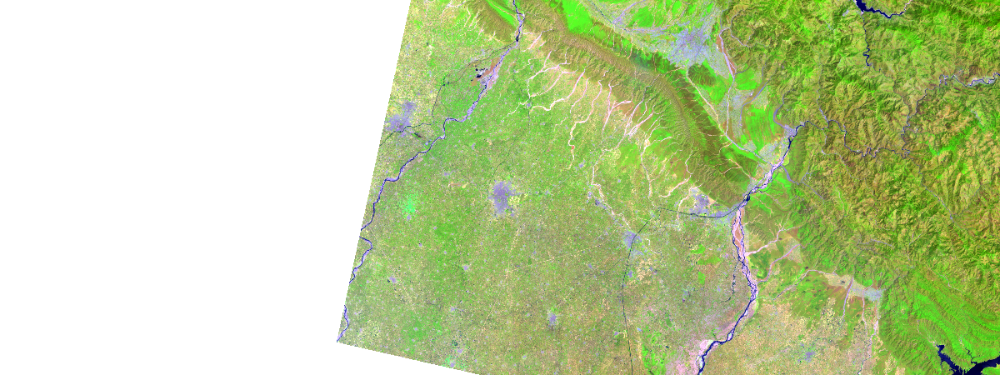

In [13]:
saharanpur_image = landsat.filter_by('OBJECTID=5066173') # 2024-04-17 05:18:42
saharanpur_image

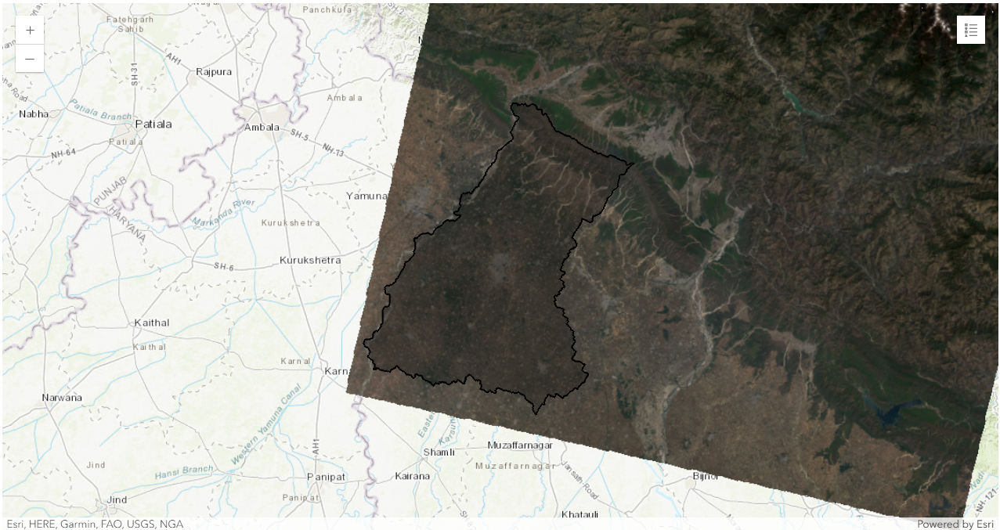

In [14]:
m1 = gis.map('Saharanpur, India')
m1.content.add(apply(saharanpur_image, 'Natural Color with DRA'))
m1.content.add(saharanpur, options = {"title" : 'Saharanpur District'})
m1.legend.enabled = True
m1

In [15]:
m1.zoom = 9

A single tile completely covers our area of interest here - 5066173, if our area of interest is larger and can not be enclosed within the tile we have chosen,  then a mosaic of two images can be created to enclose the AOI. Mosaicking two rasters with OBJECTID - 5035681 and 5066173 using predefined [mosaic_by](https://developers.arcgis.com/python/api-reference/arcgis.raster.toc.html?highlight=mosaic_by#arcgis.raster.ImageryLayer.mosaic_by) function.

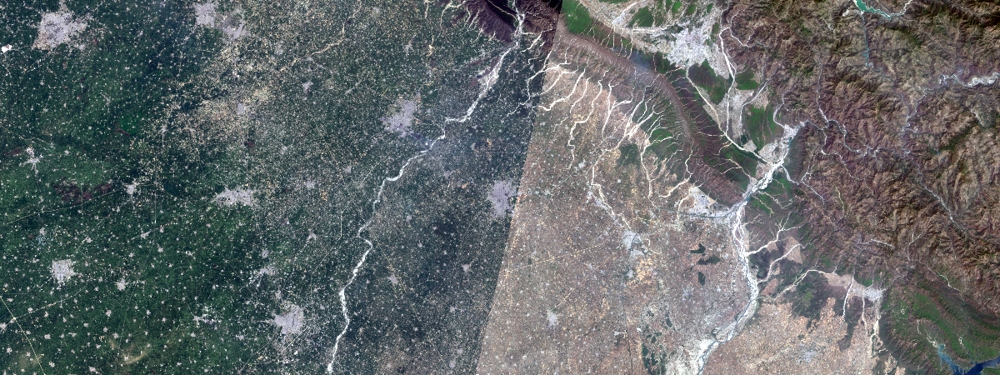

In [16]:
landsat.mosaic_by(method = "LockRaster", lock_rasters = [5035681, 5066173])
mosaic = apply(landsat, 'Natural Color with DRA')
mosaic

We will clip the mosaicked raster using the boundary of Saharanpur which is our area of interest using [clip](https://developers.arcgis.com/python/api-reference/arcgis.raster.functions.html?highlight=clip#clip) function.

In [17]:
saharanpur_raster_clip = arcgis.raster.functions.clip(mosaic, saharanpur_geom)
saharanpur_raster_clip.extent = extent
arcgis.env.analysis_extent = extent

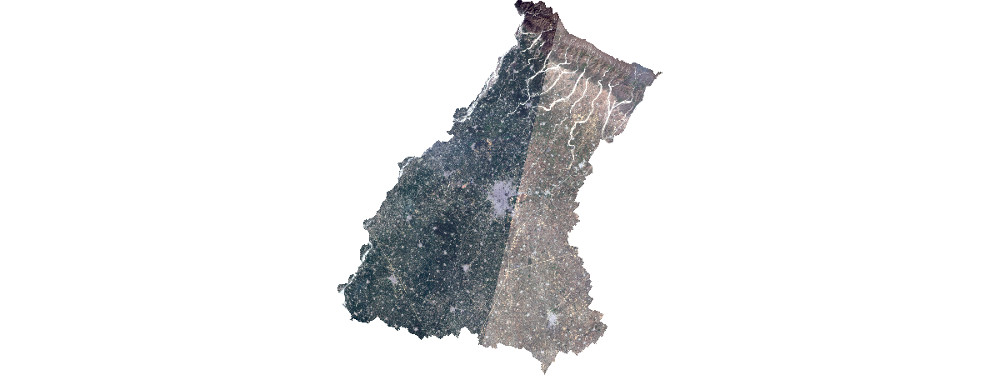

In [18]:
saharanpur_raster_clip

In [19]:
clip_out_name = 'saharanpur_raster_clip' + str(datetime.date.today()).replace("-", "")
saharanpur_raster_clip.save(clip_out_name, gis = gis)

<Item title:"saharanpur_raster_clip20241218" type:Tiled Imagery Layer owner:arcgis_python>

## Visualize the mosaic and training points on map

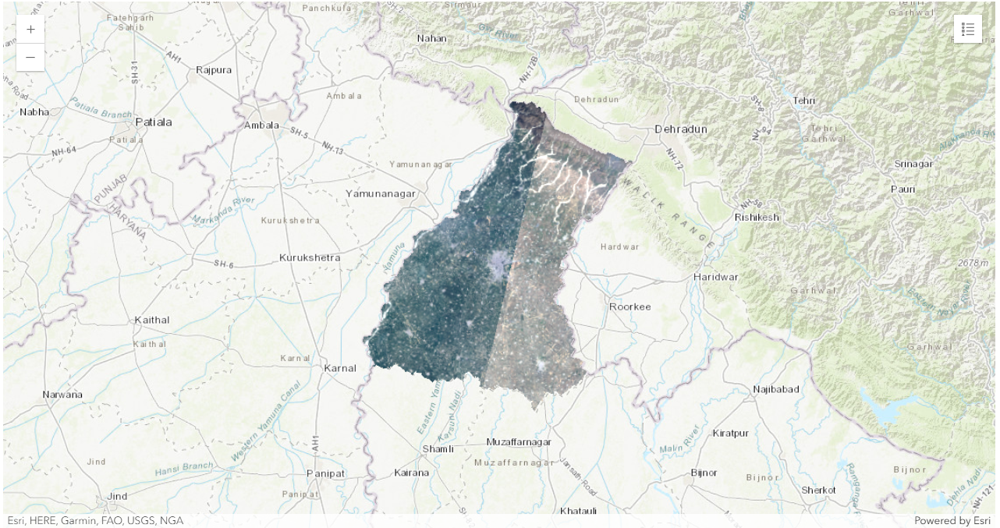

In [20]:
m2 = gis.map('Saharanpur, India')
m2.content.add(saharanpur_raster_clip)
m2.content.add(data)
m2.legend.enabled = True
m2

In [21]:
m2.zoom = 9

## Classification

With the Landsat layer and the training samples, we are now ready to train a support vector machine (SVM) model using [train_classifier](https://developers.arcgis.com/python/api-reference/arcgis.raster.analytics.html?highlight=train_classifier#arcgis.raster.analytics.train_classifier) function.

In [22]:
saharanpur_raster_clip_search = gis.content.search(clip_out_name)
saharanpur_raster_clip_search = saharanpur_raster_clip_search[0] # Check for the name of the layer if it is the same name with which you have saved it in previous steps or else try by changing indexing
saharanpur_raster_clip_search

<Item title:"saharanpur_raster_clip20241218" type:Tiled Imagery Layer owner:arcgis_python>

In [23]:
classifier_definition = train_classifier(input_raster = saharanpur_raster_clip_search, 
                                         input_training_sample_json = data.layers[0].query().to_json, 
                                         classifier_parameters = {"method":"svm",
                                                                "params":{"maxSampleClass":100}},
                                         gis = gis)

Now we have the model, we are ready to apply the model to a landsat image of Saharanpur district to make prediction. This classifier will classify each pixel of the image into 5 different classes namely <b>Urban</b>, <b>Forest</b>, <b>Agricultural</b>, <b>Water</b> and <b>Wasteland</b>. We will use predefined [classify](https://developers.arcgis.com/python/api-reference/arcgis.raster.analytics.html?highlight=classify#arcgis.raster.analytics.classify) function to perform the classification.

In [24]:
classified_output = classify(input_raster = saharanpur_raster_clip, 
                             input_classifier_definition = classifier_definition)
classified_output

<Item title:"Classify_ZVG9NR" type:Tiled Imagery Layer owner:arcgis_python>

Now let's visualize the classification result based on the colormap defined below.

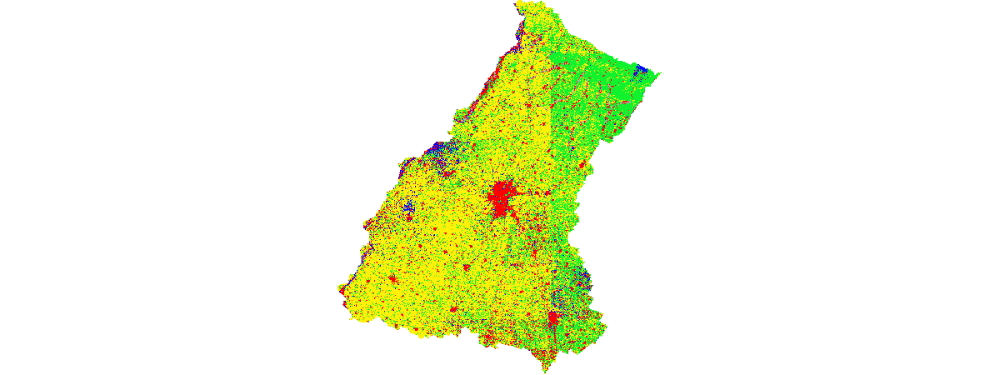

In [25]:
cmap = colormap(classified_output.layers[0],
                 colormap=[[0, 255, 0, 0],
                          [1, 15, 242, 45],
                          [2, 255, 240, 10],
                          [3, 0, 0, 255],
                          [4, 176, 176, 167]])
cmap

In [26]:
out_name = 'saharanpur_classified_output__' + str(datetime.date.today()).replace("-", "")
cmap.save(out_name, gis = gis)

<Item title:"saharanpur_classified_output__20241218" type:Tiled Imagery Layer owner:arcgis_python>

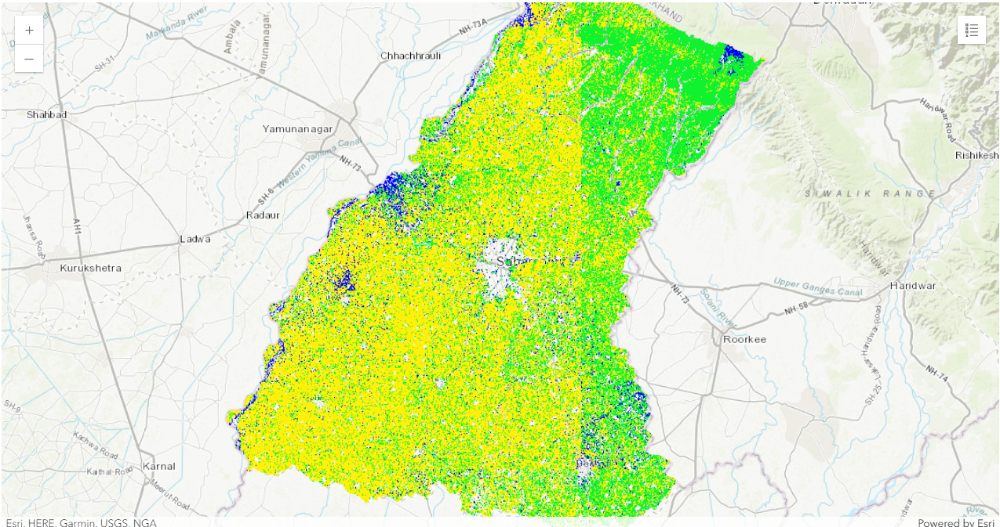

In [27]:
m3 = gis.map('Saharanpur, India')
m3.content.add(cmap)
m3.legend.enabled = True
m3

In [28]:
m3.zoom = 10

Here, '0', '1', '2', '3' and '4' represents pixels from <b>'Urban'</b>, <b>'Forest'</b>, <b>'Agricultural'</b>, <b>'Water'</b> and <b>'Wasteland'</b> class respectively.

We can see that our model is performing reasonably well and is able to clearly identify the urban settlements while comparing the prediction with the Landsat image.

### Mask settlements out of the classified raster

We have a classified raster which has each of its pixel classified against 5 different classes. But we require the pixels belonging to <b>Urban</b> class only, so we will mask all the pixels belonging to that class.

In [29]:
classified_output = gis.content.search('saharanpur_classified_output', outside_org= True)[0]
classified_output

<Item title:"saharanpur_classified_output__20241120" type:Tiled Imagery Layer owner:arcgis_python>

As we are concerned only with detecting settlement pixels, we will mask out others from the classified raster by selecting the pixels with a class value of '0' which represents <b>'Urban'</b> class.

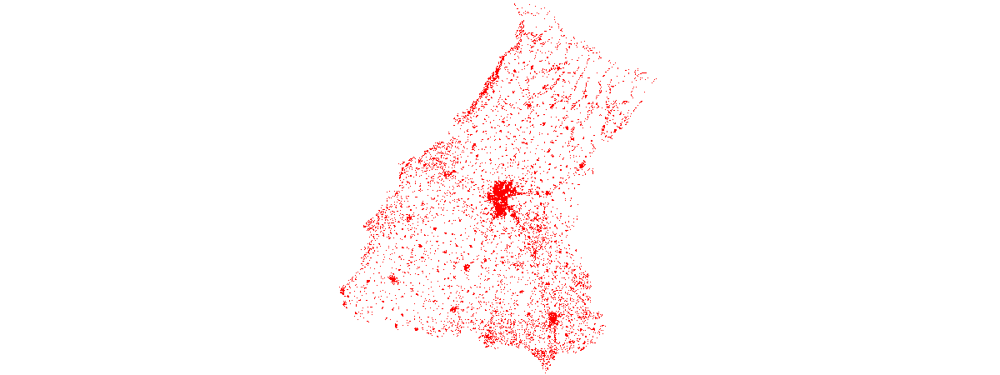

In [30]:
masked = colormap(mask(classified_output.layers[0],
                       no_data_values =[],
                       included_ranges =[0,0]),
                  colormap=[[0, 255, 0, 0]],
                  astype='u8')
masked.extent = extent
masked

We can save the masked raster containing the settlements to an imagery layer. This uses distributed raster analytics and performs the processing at the source pixel level and creates a new raster product.

In [31]:
masked = masked.save()

We can now Convert the masked pixels to polygons using <b>'to_features'</b> function.

In [32]:
urban_item = masked.layers[0].to_features(output_name='masked_polygons' + str(datetime.datetime.now().microsecond) ,
                                          output_type='Polygon',
                                          field='Value',
                                          simplify=True,
                                          gis=gis)
urban_layer = urban_item.layers[0]

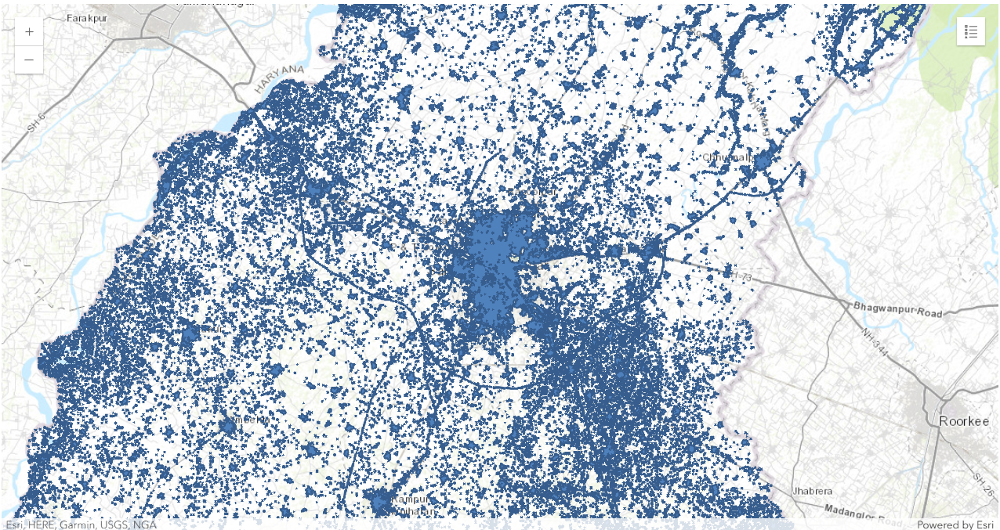

In [33]:
m4 = gis.map('Saharanpur, India')
m4.legend.enabled = True
m4.content.add(urban_item)
m4

In [34]:
m4.zoom = 11

The settlement polygons have many false positives - mainly there are areas near river bed that are confused with settlements. 

These false positives were removed by post processing using ArcGIS Pro. The result obtained after cleaning up the supervised classification are shown below, which are the final detected settlements.

In [35]:
settlement_poly = gis.content.search("'settlement_polygons'", outside_org= True)

## Deep Learning

The deep learning approach for classification needs more training data. We will use the results that we obtained after cleaning up false positives from SVM predictions above, and exported training chips against each of those polygons using ArcGIS pro to train a deep learning model.

### Export training data

Export training data using 'Export Training data for deep learning' tool, detailed documentation here

- Set Landsat imagery as 'Input Raster'.
- Set a location where you want to export the training data, it can be an existing folder or the tool will create that for you.
- Set the settlement training polygons as input to the 'Input Feature Class Or Classified Raster' parameter.
- In the option 'Input Mask Polygons' we can set a mask layer to limit the tool to export training data for only those areas which have buildings in it, we created one by generating a grid of 200m by 200m on Urban Polygons layer's extent and dissolving only those polygons which contained settlements to a single multipolygon feature.
- 'Tile Size X' & 'Tile Size Y' can be set to 224.
- Select 'Classified Tiles' as the 'Meta Data Format' because we are training an 'Unet Model'.
- In 'Environments' tab set an optimum 'Cell Size'. For this example, as we have performing the analysis on Landsat8 imagery, we used 30 cell size which meant 30m on a project coordinate system.

<img src="data:image/PNG; base64, ...">


### Prepare data

We would specify the path to our training data and a few hyper parameters.

- `path`: path of folder containing training data.
- `batch_size`: No of images your model will train on each step inside an epoch, it directly depends on the memory of your graphic card. 8 worked for us on a 11GB GPU.
- `imagery_type`: It is a mandatory input to enable model for multispectral data processing. It can be "landsat8", "sentinel2", "naip", "ms" or "multispectral".

In [36]:
import os
from pathlib import Path

gis = GIS('home')

<Item title:"detecting_settlements_using_supervised_classification_and_deep_learning" type:Image Collection owner:api_data_owner>
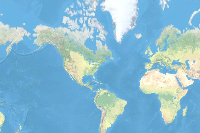

In [37]:
training_data = gis.content.get('b9602a576cd54bc6a8e0279a290537af')
training_data

In [38]:
filepath = training_data.download(file_name=training_data.name)

In [39]:
import zipfile
with zipfile.ZipFile(filepath, 'r') as zip_ref:
    zip_ref.extractall(Path(filepath).parent)

In [40]:
data_path = Path(os.path.join(filepath.split('.')[0]))

In [41]:
# Prepare Data
data = prepare_data(data_path,
                    batch_size=8,
                    imagery_type='landsat8')

For our model, we want out of the 11 bands in Landsat 8 image, weights for the RGB bands to be initialized using ImageNet weights whereas the other bands should have their weights initialized using the red band values. We can do this by setting the "type_init" parameter in the environment as "red band".

In [42]:
arcgis.env.type_init = 'red_band'

### Visualize training data

The code below shows a few samples of our data with the same symbology as in ArcGIS Pro.

- `rows`: No. of rows we want to see the results for.
- `alpha`: controls the opacity of labels (Classified imagery) over the background imagery
- `statistics_type`: for dynamic range adjustment

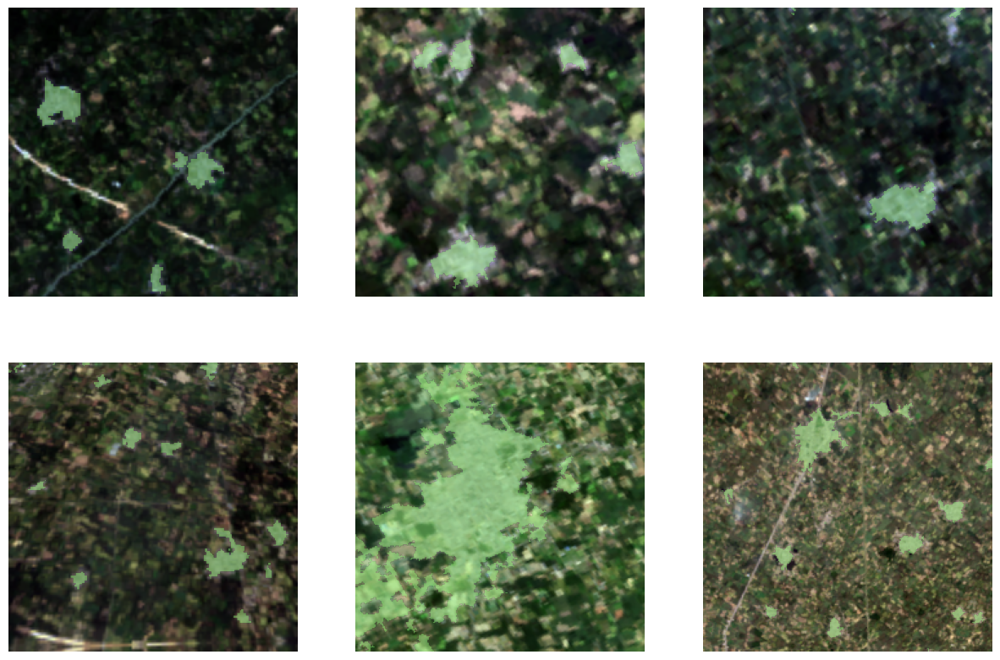

In [43]:
data.show_batch(rows=2, alpha=0.7, statistics_type='DRA')

Here, the light blue patches show the labelled settlements.

### Load model architecture

We will be using U-net [4], one of the well recognized image segmentation algorithm, for our land cover classification. U-Net is designed like an auto-encoder. It has an encoding path (“contracting”) paired with a decoding path (“expanding”) which gives it the “U” shape. However, in contrast to the autoencoder, U-Net predicts a pixelwise segmentation map of the input image rather than classifying the input image as a whole. For each pixel in the original image, it asks the question: “To which class does this pixel belong?”. U-Net passes the feature maps from each level of the contracting path over to the analogous level in the expanding path. These are similar to residual connections in a ResNet type model, and allow the classifier to consider features at various scales and complexities to make its decision.

In [44]:
# Create Unet Model
model = UnetClassifier(data)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to ~/.cache\torch\hub\checkpoints\resnet34-b627a593.pth
100%|█████████████████████████████████████████████████████████████████████| 83.3M/83.3M [00:07<00:00, 11.0MB/s]


### Train the model

By default, the U-Net model uses ImageNet weights which are trained on 3 band imagery but we are using the multispectral support of ArcGIS API for Python to train the model for detecting settlements on 11 band Landsat 8 imagery, so unfreezing will make the backbone trainable so that it can learn to extract features from multispectral data. 

Before training the model, let's unfreeze it to train it from scratch. 

In [45]:
model.unfreeze()

Learning rate is one of the most important hyperparameters in model training. Here, we explore a range of learning rate to guide us to choose the best one.

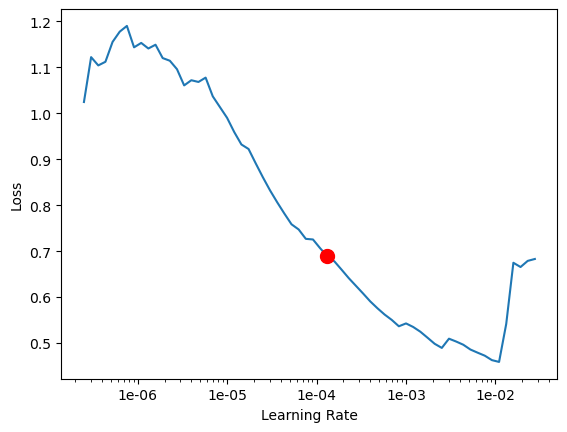

0.00013182567385564074

In [46]:
# Find Learning Rate
model.lr_find()

Based on the learning rate plot above, we can see that the learning rate suggested by `lr_find()` for our training data is 0.0002754228703338166. We can use it to train our model.

We would fit the model for 100 epochs. One epoch mean the model will see the complete training set once.

In [47]:
# Training
model.fit(epochs=100, lr=0.00022908676527677726);

epoch,train_loss,valid_loss,accuracy,dice,time
0,0.945803,0.435032,0.843142,0.321884,00:03
1,0.635342,0.190144,0.956304,0.318480,00:02
2,0.488440,0.151087,0.966368,0.130729,00:02
3,0.426781,0.143472,0.969393,0.090011,00:02
4,0.383520,0.118604,0.969702,0.154901,00:02
5,0.344074,0.163483,0.970603,0.443173,00:02
6,0.308062,0.198724,0.961839,0.508260,00:02
7,0.282400,0.114322,0.974624,0.452691,00:02
8,0.265542,0.091364,0.975506,0.396909,00:02
9,0.246890,0.158701,0.970902,0.598874,00:02


In [48]:
model.mIOU()

{'0': 0.9867301422601041, '1': 0.6107132199252355}

Here, we can see loss on both training and validation set decreasing, which shows how well the model generalizes on unseen data thereby preventing overfitting. Also, as we can see our model here is able to classify pixels to settlement or non settlement with an accuracy 0.98. Once we are satisfied with the accuracy, we can save the model.

### Save the model

We would now save the model which we just trained as a 'Deep Learning Package' or '.dlpk' format. Deep Learning package is the standard format used to deploy deep learning models on the ArcGIS platform. UnetClassifier models can be deployed by the tool 'Classify Pixels Using Deep Learning' available in ArcGIS Pro as well as ArcGIS Enterprise. For this sample, we will be using this model in ArcGIS Pro to extract settlements.

We will use the `save()` method to save the model and by default it will be saved to a folder 'models' inside our training data folder itself.

In [49]:
model.save('100e')

Computing model metrics...


WindowsPath('~/AppData/Local/Temp/detecting_settlements_using_supervised_classification_and_deep_learning/models/100e')

### Load an intermediate model to train it further

If we need to further train an already saved model we can load it again using the code below and repeat the earlier mentioned steps of training.

In [50]:
# Load Model from previous saved files 
# model.load('100e')

### Preview results

The code below will pick a few random samples and show us ground truth and respective model predictions side by side. This allows us to validate the results of your model in the notebook itself. Once satisfied we can save the model and use it further in our workflow.

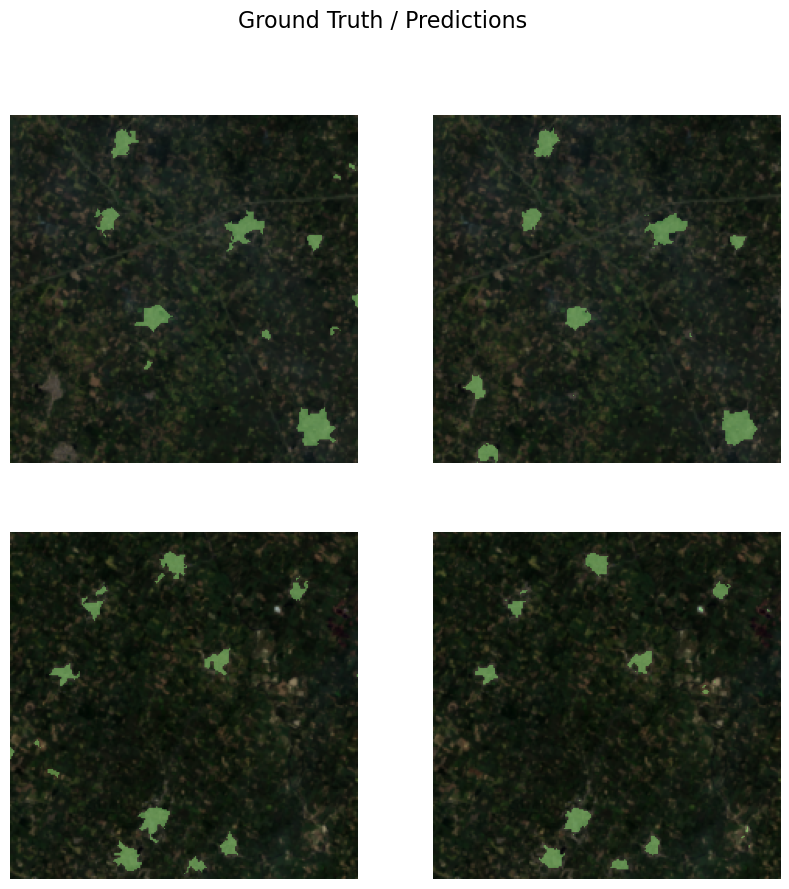

In [51]:
model.show_results(rows=2)

### Deploy model and extract settlements

The model saved in previous step can be used to extract classified raster using <b>'Classify Pixels Using Deep Learning'</b> tool. Further the classified raster is regularised and finally converted to a vector Polygon layer. The regularisation step uses advanced ArcGIS geoprocessing tools to remove unwanted artifacts in the output.

### Generate a classified raster

In this step, we will generate a classified raster using <b>'Classify Pixels Using Deep Learning'</b> tool available in both ArcGIS Pro and ArcGIS Enterprise.

- `Input Raster`: The raster layer from which we want to extract settlements from.
- `Model Definition`: It will be located inside the saved model in 'models' folder in '.emd' format.
- `Padding`: The 'Input Raster' is tiled and the deep learning model classifies each individual tile separately before producing the final 'Output Classified Raster'. This may lead to unwanted artifacts along the edges of each tile as the model has little context to predict accurately. Padding as the name suggests allows us to supply some extra information along the tile edges, this helps the model to predict better.
- `Cell Size`: Should be close to at which we trained the model, we specified that at the Export training data step .
- `Processor Type`: This allows to control whether the system's 'GPU' or 'CPU' would be used in to classify pixels, by 'default GPU' will be used if available.
- `Parallel Processing Factor`: This allows us to scale this tool, this tool can be scaled on both 'CPU' and 'GPU'. It specifies that the operation would be spread across how many 'cpu cores' in case of cpu based operation or 'no of GPU's' in case of GPU based operation.

<img src="data:image/PNG; base64, ...">


Output of this tool will be in form of a 'classified raster' containing both background and Settlements. The pixels having background class are shown in green color and pixels belonging to settlement class are in purple color.

<img src="data:image/PNG; base64, ...">

                                    
                                            A subset of preditions by our Model

Change the symbology of the raster by setting the second class of the classified pixels to <b>'No color'</b>.

<img src="data:image/PNG; base64, ...">


After this step, we will get a masked raster which will look like the screenshot below.

<img src="data:image/PNG; base64, ...">


We can now run <b>'Raster to Polygon'</b> tool in ArcGIS Pro to convert this masked raster to polygons.

<img src="data:image/PNG; base64, ...">


Results obtained from Deep Learning approach are ready to be analyzed.

<img src="data:image/PNG; base64, ...">

                 Deep Learning Results

## Conclusion

This notebook shows how traditional algorithms like Support Vector Machines can be used to generate the necessary quality data for Deep Learning models which after cleaning can serve as the training data required by a DL model for generating accurate results at a much larger extent. 

## References 

[1] https://developers.arcgis.com/python/sample-notebooks/detecting-swimming-pools-using-satellite-image-and-deep-learning/ 

[2] https://developers.arcgis.com/python/sample-notebooks/extracting-building-footprints-from-drone-data/

[3] https://developers.arcgis.com/python/sample-notebooks/land-cover-classification-using-unet/

[4] Olaf Ronneberger, Philipp Fischer, Thomas Brox: U-Net: Convolutional Networks for Biomedical Image Segmentation, 2015; [arXiv:1505.04597](https://arxiv.org/abs/1505.04597).